# 🔬 Arabic Summarization Baseline — AraT5 WITHOUT Domain Classification
> **NLP Project | Kaggle Notebook — Ablation / Baseline**  
> Fine-tuning **AraT5** on ArabSummaries **without** any domain prefix or domain-aware training.

---
## 🎯 Purpose
This notebook is the **control experiment** to compare against the multi-domain notebook.

| | This notebook (Baseline) | Multi-Domain notebook |
|---|---|---|
| Domain classification | ❌ None | ✅ Keyword-based |
| Training prefix | `لخص: <text>` | `لخص [domain]: <text>` |
| Stratified split | ❌ Random | ✅ Stratified by domain |
| ROUGE evaluated per domain | ❌ | ✅ |
| Model | AraT5v2-base | AraT5v2-base (same) |
| Dataset | ArabSummaries (same) | ArabSummaries (same) |
| Hyperparameters | identical | identical |

> **Everything else is identical** — same model, same data, same hyperparameters.  
> Any ROUGE difference is due to domain conditioning alone.

---
## 📌 Pipeline
```
1.  Install Dependencies
2.  Import Libraries
3.  Load Dataset
4.  EDA
5.  Preprocessing & Cleaning
6.  Train / Val / Test Split (random, no stratification)
7.  Tokenization (plain prefix — no domain)
8.  Load Model & Configure Training
9.  Train
10. Evaluation (overall ROUGE only)
11. Sample Predictions
12. Interactive Demo (no domain selector)
13. Save Model + Comparison Summary
```
---
### ⚙️ Kaggle Settings
- **Accelerator**: GPU T4 x1
- **Internet**: ON
- **Persistence**: Files


## Step 1 — Install Dependencies

In [ ]:
import subprocess, sys

pkgs = [
    'transformers==4.44.2',
    'datasets==2.21.0',
    'accelerate==0.34.2',
    'evaluate==0.4.3',
    'sentencepiece',
    'ipywidgets',
    'scikit-learn',
]
for pkg in pkgs:
    r = subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', pkg],
        capture_output=True, text=True
    )
    print(('✅' if r.returncode == 0 else '❌'), pkg)

print('\n⚠️  IMPORTANT: Restart session then run all cells again.')

## Step 2 — Import Libraries

In [2]:
import os, re, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    GenerationConfig,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)

warnings.filterwarnings('ignore')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'✅ Device: {device}')
if device == 'cuda':
    print(f'   GPU   : {torch.cuda.get_device_name(0)}')
    print(f'   Memory: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    print('⚠️  No GPU detected!')

✅ Device: cuda
   GPU   : Tesla T4
   Memory: 15.6 GB


In [3]:
# ── ContiguousSeq2SeqTrainer — fixes non-contiguous tensor crash ─────────────
# T5/AraT5 uses tied/shared weight matrices. After fp16 training these become
# non-contiguous memory views that safetensors refuses to serialize.
# This subclass overrides _save() so tensors are made contiguous BEFORE every
# checkpoint save — including the internal saves the Trainer does after each epoch.
from transformers import Seq2SeqTrainer as _BaseTrainer

class ContiguousSeq2SeqTrainer(_BaseTrainer):
    def _save(self, output_dir=None, state_dict=None):
        for param in self.model.parameters():
            if not param.data.is_contiguous():
                param.data = param.data.contiguous()
        super()._save(output_dir=output_dir, state_dict=state_dict)

print('✅ ContiguousSeq2SeqTrainer ready — checkpoint saves will not crash.')

✅ ContiguousSeq2SeqTrainer ready — checkpoint saves will not crash.


## Step 3 — Load Dataset

In [4]:
CSV_PATH = '/kaggle/input/datasets/tahaalselwii/arabsummaries/ArabSummaries.csv'

df_raw = pd.read_csv(CSV_PATH)
print(f'📊 Shape   : {df_raw.shape}')
print(f'   Columns : {list(df_raw.columns)}')
df_raw.head(3)

📊 Shape   : (7000, 5)
   Columns : ['text', 'summary', 'type', 'text_length', 'summary_length']


,text,summary,type,text_length,summary_length
0,ينظم معهد الشارقة للفنون معرضاً فنياً تحت عنوا...,"ينظم معهد الشارقة للفنون معرضاً فنياً بعنوان ""...",Culture,246,150
1,تقيم الفنانة ليتا كابيلوت معرضاً في مطلع العام...,تقيم الفنانة ليتا كابيلوت معرضاً في دبي مطلع ا...,Culture,963,471
2,تتواصل الليلة مسيرة التحدّي والمتعة والإثارة ض...,تستمر الليلة منافسات برنامج شاعر المليون، حيث ...,Culture,1717,426


In [5]:
print('Column samples:')
for col in df_raw.columns:
    print(f'  [{col}]:', str(df_raw[col].iloc[0])[:120])

# ⚠️ Update to match your actual column names
TEXT_COL    = 'article'
SUMMARY_COL = 'summary'

df = df_raw.rename(columns={TEXT_COL: 'text', SUMMARY_COL: 'summary'})
df = df[['text', 'summary']].dropna().reset_index(drop=True)
print(f'\n✅ Loaded {len(df):,} samples')
df.head(2)

Column samples:
  [text]: ينظم معهد الشارقة للفنون معرضاً فنياً تحت عنوان باقة الفن، وذلك عند الساعة السابعة من مساء اليوم في مقر المعهد في منطقة 
  [summary]: ينظم معهد الشارقة للفنون معرضاً فنياً بعنوان "باقة الفن" اليوم الساعة السابعة مساءً في مقر المعهد، بمشاركة إبداعات 62 طا
  [type]: Culture
  [text_length]: 246
  [summary_length]: 150

✅ Loaded 7,000 samples


,text,summary
0,ينظم معهد الشارقة للفنون معرضاً فنياً تحت عنوا...,"ينظم معهد الشارقة للفنون معرضاً فنياً بعنوان ""..."
1,تقيم الفنانة ليتا كابيلوت معرضاً في مطلع العام...,تقيم الفنانة ليتا كابيلوت معرضاً في دبي مطلع ا...


## Step 4 — EDA

       text_words  summary_words    ratio
count     7000.00        7000.00  7000.00
mean       368.80          73.18     0.33
std        340.77          20.28     0.19
min         13.00          13.00     0.03
25%        141.00          61.00     0.18
50%        255.00          74.00     0.30
75%        477.00          86.00     0.44
max       3042.00         257.00     1.55


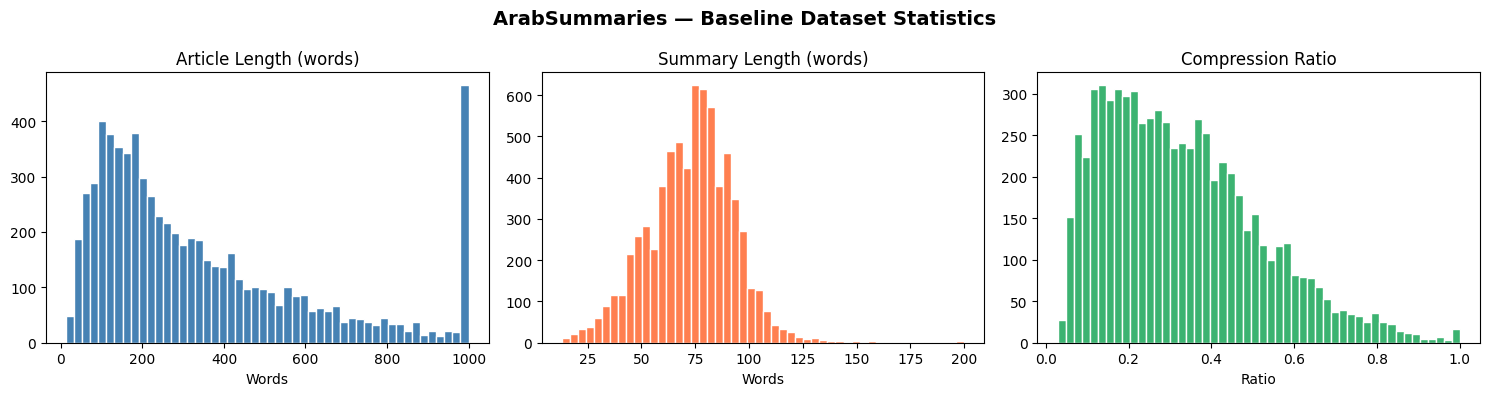

✅ EDA complete


In [6]:
df['text_words']    = df['text'].apply(lambda x: len(str(x).split()))
df['summary_words'] = df['summary'].apply(lambda x: len(str(x).split()))
df['ratio']         = df['summary_words'] / df['text_words'].replace(0, 1)

print(df[['text_words','summary_words','ratio']].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('ArabSummaries — Baseline Dataset Statistics', fontsize=14, fontweight='bold')
axes[0].hist(df['text_words'].clip(0,1000),   bins=50, color='steelblue',     edgecolor='white')
axes[0].set_title('Article Length (words)'); axes[0].set_xlabel('Words')
axes[1].hist(df['summary_words'].clip(0,200), bins=50, color='coral',         edgecolor='white')
axes[1].set_title('Summary Length (words)'); axes[1].set_xlabel('Words')
axes[2].hist(df['ratio'].clip(0,1),           bins=50, color='mediumseagreen', edgecolor='white')
axes[2].set_title('Compression Ratio');      axes[2].set_xlabel('Ratio')
plt.tight_layout()
plt.savefig('eda_baseline.png', dpi=120, bbox_inches='tight')
plt.show()
print('✅ EDA complete')

## Step 5 — Preprocessing & Cleaning

In [7]:
def clean_arabic(text: str) -> str:
    if not isinstance(text, str):
        return ''
    text = re.sub(r'[^\u0600-\u06FF\u0750-\u077F\s،؟!.]', ' ', text)
    text = re.sub(r'[\u064B-\u065F]', '', text)   # remove tashkeel
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['text']    = df['text'].apply(clean_arabic)
df['summary'] = df['summary'].apply(clean_arabic)

mask = (
    df['text'].str.split().str.len().between(50, 800) &
    df['summary'].str.split().str.len().between(15, 150)
)
df_clean = df[mask].reset_index(drop=True)
print(f'✅ After cleaning: {len(df_clean):,} samples  (removed {len(df)-len(df_clean):,})')
df_clean[['text','summary']].head(2)

✅ After cleaning: 6,118 samples  (removed 882)


,text,summary
0,تقيم الفنانة ليتا كابيلوت معرضا في مطلع العام ...,تقيم الفنانة ليتا كابيلوت معرضا في دبي مطلع ال...
1,تتواصل الليلة مسيرة التحدي والمتعة والإثارة ضم...,تستمر الليلة منافسات برنامج شاعر المليون، حيث ...


## Step 6 — Train / Val / Test Split
> ⚠️ **Baseline difference**: plain random split — no stratification by domain.

In [8]:
# Plain random split — intentionally NO stratify= argument
train_df, temp_df = train_test_split(df_clean, test_size=0.2, random_state=42)
val_df,  test_df  = train_test_split(temp_df,  test_size=0.5, random_state=42)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)
print(f'Train : {len(train_df):,}  |  Val : {len(val_df):,}  |  Test : {len(test_df):,}')

Train : 4,894  |  Val : 612  |  Test : 612


## Step 7 — Tokenization (plain prefix, no domain)
> ⚠️ **Baseline difference**: prefix is simply `لخص: <text>` — no domain tag.

In [9]:
MODEL_NAME = 'UBC-NLP/AraT5v2-base-1024'
MAX_INPUT  = 512
MAX_TARGET = 128

print(f'Loading tokenizer: {MODEL_NAME} ...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f'✅ Tokenizer loaded  (vocab: {tokenizer.vocab_size:,})')

# ── Plain prefix — NO domain information ─────────────────────────────────────
def make_prefix(text: str) -> str:
    return f'لخص: {text}'

sample = make_prefix(df_clean['text'].iloc[0])
print(f'\nPrefix example (first 100 chars):\n  {sample[:100]}...')

Loading tokenizer: UBC-NLP/AraT5v2-base-1024 ...
✅ Tokenizer loaded  (vocab: 110,100)

Prefix example (first 100 chars):
  لخص: تقيم الفنانة ليتا كابيلوت معرضا في مطلع العام المقبل في دبي، ويضم المعرض لوحة، تركز خلالها على ...


In [10]:
def tokenize_batch(examples):
    prefixed_texts = [make_prefix(t) for t in examples['text']]

    model_inputs = tokenizer(
        prefixed_texts,
        max_length=MAX_INPUT,
        truncation=True,
        padding='max_length',
    )
    labels = tokenizer(
        text_target=examples['summary'],
        max_length=MAX_TARGET,
        truncation=True,
        padding='max_length',
    )
    model_inputs['labels'] = [
        [(tok if tok != tokenizer.pad_token_id else -100) for tok in lab]
        for lab in labels['input_ids']
    ]
    return model_inputs

train_ds = Dataset.from_pandas(train_df[['text','summary']])
val_ds   = Dataset.from_pandas(val_df[['text','summary']])
test_ds  = Dataset.from_pandas(test_df[['text','summary']])

print('Tokenizing...')
train_tok = train_ds.map(tokenize_batch, batched=True, batch_size=64, remove_columns=['text','summary'])
val_tok   = val_ds.map(tokenize_batch,   batched=True, batch_size=64, remove_columns=['text','summary'])
test_tok  = test_ds.map(tokenize_batch,  batched=True, batch_size=64, remove_columns=['text','summary'])
print(f'✅ Train={len(train_tok):,} | Val={len(val_tok):,} | Test={len(test_tok):,}')

Tokenizing...


Map:   0%|          | 0/4894 [00:00<?, ? examples/s]

Map:   0%|          | 0/612 [00:00<?, ? examples/s]

Map:   0%|          | 0/612 [00:00<?, ? examples/s]

✅ Train=4,894 | Val=612 | Test=612


## Step 8 — Load Model & Configure Training

In [11]:
print(f'Loading model: {MODEL_NAME} ...')
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
print(f'✅ Model loaded  ({sum(p.numel() for p in model.parameters()):,} params)')

gen_config = GenerationConfig(
    decoder_start_token_id = model.config.decoder_start_token_id,
    bos_token_id           = model.config.bos_token_id,
    eos_token_id           = model.config.eos_token_id,
    pad_token_id           = model.config.pad_token_id,
    no_repeat_ngram_size   = 3,
    num_beams              = 4,
    max_new_tokens         = MAX_TARGET,
)
model.generation_config = gen_config
print('✅ GenerationConfig set')

Loading model: UBC-NLP/AraT5v2-base-1024 ...
✅ Model loaded  (367,508,736 params)
✅ GenerationConfig set


In [12]:
# ── Manual ROUGE ──────────────────────────────────────────────────────────────
def get_ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens)-n+1)]

def rouge_n_score(pred_tokens, ref_tokens, n):
    pred_ng = Counter(get_ngrams(pred_tokens, n))
    ref_ng  = Counter(get_ngrams(ref_tokens,  n))
    overlap  = sum((pred_ng & ref_ng).values())
    prec = overlap / max(sum(pred_ng.values()), 1)
    rec  = overlap / max(sum(ref_ng.values()),  1)
    return (2*prec*rec/(prec+rec)) if (prec+rec) > 0 else 0.0

def lcs_len(x, y):
    dp = [[0]*(len(y)+1) for _ in range(len(x)+1)]
    for i in range(1, len(x)+1):
        for j in range(1, len(y)+1):
            dp[i][j] = dp[i-1][j-1]+1 if x[i-1]==y[j-1] else max(dp[i-1][j], dp[i][j-1])
    return dp[len(x)][len(y)]

def rouge_l_score(pred_tokens, ref_tokens):
    lcs  = lcs_len(pred_tokens, ref_tokens)
    prec = lcs / max(len(pred_tokens), 1)
    rec  = lcs / max(len(ref_tokens),  1)
    return (2*prec*rec/(prec+rec)) if (prec+rec) > 0 else 0.0

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    if predictions.ndim == 3:
        predictions = np.argmax(predictions, axis=-1)
    vocab_size  = tokenizer.vocab_size
    predictions = np.clip(predictions, 0, vocab_size-1).astype(np.int32)
    labels      = np.where(labels != -100, labels, tokenizer.pad_token_id)
    labels      = np.clip(labels, 0, vocab_size-1).astype(np.int32)
    decoded_preds  = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels,      skip_special_tokens=True)
    r1, r2, rL = [], [], []
    for pred, ref in zip(decoded_preds, decoded_labels):
        pt = pred.split(); rt = ref.split()
        r1.append(rouge_n_score(pt, rt, 1))
        r2.append(rouge_n_score(pt, rt, 2))
        rL.append(rouge_l_score(pt, rt))
    return {
        'rouge1': round(float(np.mean(r1))*100, 2),
        'rouge2': round(float(np.mean(r2))*100, 2),
        'rougeL': round(float(np.mean(rL))*100, 2),
    }

print('✅ ROUGE metrics ready')

✅ ROUGE metrics ready


In [13]:
OUTPUT_DIR = '/kaggle/working/arabic-arat5-baseline'

# ── Identical hyperparameters to the multi-domain notebook ───────────────────
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=4,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    warmup_steps=200,
    learning_rate=3e-4,
    weight_decay=0.01,
    evaluation_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='rougeL',
    greater_is_better=True,
    predict_with_generate=True,
    # NOTE: no generation_max_length — controlled via GenerationConfig
    fp16=torch.cuda.is_available(),
    logging_dir=f'{OUTPUT_DIR}/logs',
    logging_steps=50,
    report_to='none',
    save_total_limit=2,
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer, model=model, label_pad_token_id=-100, pad_to_multiple_of=8
)

trainer = ContiguousSeq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print('✅ Trainer ready!')

✅ Trainer ready!


## Step 9 — Train 🚀
> ⏱️ ~60–90 min on Kaggle T4 GPU

In [ ]:
print('🚀 Starting training (BASELINE — no domain)...')
print('='*50)
train_result = trainer.train()
print('='*50)
print(f'✅ Training complete!')
print(f'   Steps        : {train_result.global_step}')
print(f'   Training loss: {train_result.training_loss:.4f}')

trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print(f'   Saved to: {OUTPUT_DIR}')

🚀 Starting training (BASELINE — no domain)...


Epoch,Training Loss,Validation Loss


## Step 10 — Evaluation (Overall ROUGE)

In [ ]:
model.eval()

def generate_summary(text: str, num_beams: int = 4) -> str:
    """Generate summary — no domain prefix."""
    prefixed = make_prefix(text)
    inputs = tokenizer(
        prefixed, return_tensors='pt',
        max_length=MAX_INPUT, truncation=True, padding=True
    ).to(device)
    with torch.no_grad():
        out = model.generate(
            input_ids      = inputs['input_ids'],
            attention_mask = inputs['attention_mask'],
            max_new_tokens = MAX_TARGET,
            num_beams      = num_beams,
            no_repeat_ngram_size = 3,
            early_stopping = True,
        )
    return tokenizer.decode(out[0], skip_special_tokens=True)

N = min(50, len(test_df))
samples = test_df.sample(N, random_state=42).reset_index(drop=True)

r1_list, r2_list, rL_list = [], [], []
print(f'Evaluating on {N} test samples...')
for _, row in samples.iterrows():
    pred = generate_summary(row['text'])
    ref  = row['summary']
    pt, rt = pred.split(), ref.split()
    r1_list.append(rouge_n_score(pt, rt, 1))
    r2_list.append(rouge_n_score(pt, rt, 2))
    rL_list.append(rouge_l_score(pt, rt))

BASELINE_R1 = np.mean(r1_list)*100
BASELINE_R2 = np.mean(r2_list)*100
BASELINE_RL = np.mean(rL_list)*100

print('\n' + '='*45)
print('   BASELINE TEST RESULTS — AraT5 (no domain)')
print('='*45)
print(f'  ROUGE-1 : {BASELINE_R1:.2f}%')
print(f'  ROUGE-2 : {BASELINE_R2:.2f}%')
print(f'  ROUGE-L : {BASELINE_RL:.2f}%')
print('='*45)
print('\n📋 Copy these numbers into the comparison cell below.')
print(f'   BASELINE_R1 = {BASELINE_R1:.2f}')
print(f'   BASELINE_R2 = {BASELINE_R2:.2f}')
print(f'   BASELINE_RL = {BASELINE_RL:.2f}')

In [ ]:
# ── Plot baseline ROUGE ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    ['ROUGE-1','ROUGE-2','ROUGE-L'],
    [BASELINE_R1, BASELINE_R2, BASELINE_RL],
    color=['steelblue','coral','mediumseagreen'], edgecolor='white', width=0.5
)
for bar, val in zip(bars, [BASELINE_R1, BASELINE_R2, BASELINE_RL]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
ax.set_ylim(0, 100)
ax.set_ylabel('Score (%)')
ax.set_title('Baseline (No Domain) — ROUGE Scores on Test Set')
ax.axhline(y=30, color='red', linestyle='--', alpha=0.4, label='~30% baseline')
ax.legend()
plt.tight_layout()
plt.savefig('rouge_baseline.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 10b — Side-by-Side Comparison Chart

> After running **both** notebooks, fill in the multi-domain scores below to generate the comparison chart.
> The multi-domain scores are printed at the end of the other notebook's Step 11.

In [ ]:
# ── Paste your multi-domain results here after running the other notebook ─────
MULTIDOMAIN_R1 = 0.0   # ← replace with actual value
MULTIDOMAIN_R2 = 0.0   # ← replace with actual value
MULTIDOMAIN_RL = 0.0   # ← replace with actual value

# Skip chart if multi-domain not filled in yet
if MULTIDOMAIN_RL == 0.0:
    print('⚠️  Fill in MULTIDOMAIN_R1/R2/RL above after running the multi-domain notebook.')
else:
    metrics   = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L']
    baseline  = [BASELINE_R1,    BASELINE_R2,    BASELINE_RL]
    multidomain = [MULTIDOMAIN_R1, MULTIDOMAIN_R2, MULTIDOMAIN_RL]

    x = np.arange(len(metrics))
    w = 0.35

    fig, ax = plt.subplots(figsize=(9, 5))
    bars1 = ax.bar(x - w/2, baseline,    w, label='Baseline (no domain)', color='steelblue',   alpha=0.85)
    bars2 = ax.bar(x + w/2, multidomain, w, label='Multi-Domain (with domain)', color='darkorange', alpha=0.85)

    for bars in [bars1, bars2]:
        for bar in bars:
            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.4,
                f'{bar.get_height():.1f}%',
                ha='center', va='bottom', fontsize=9, fontweight='bold'
            )

    # Annotate deltas
    for i, (b, m) in enumerate(zip(baseline, multidomain)):
        delta = m - b
        color = 'green' if delta >= 0 else 'red'
        sign  = '+' if delta >= 0 else ''
        ax.annotate(
            f'{sign}{delta:.1f}%',
            xy=(x[i] + w/2, m + 1.5),
            ha='center', color=color, fontsize=9, fontweight='bold'
        )

    ax.set_xticks(x)
    ax.set_xticklabels(metrics, fontsize=11)
    ax.set_ylabel('Score (%)', fontsize=11)
    ax.set_ylim(0, 100)
    ax.set_title('AraT5: Baseline vs Multi-Domain — ROUGE Comparison', fontsize=13, fontweight='bold')
    ax.legend(fontsize=10)
    ax.axhline(y=30, color='grey', linestyle='--', alpha=0.4, label='30% reference')
    plt.tight_layout()
    plt.savefig('rouge_comparison.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('✅ Comparison chart saved to rouge_comparison.png')

    winner = 'Multi-Domain' if MULTIDOMAIN_RL > BASELINE_RL else 'Baseline'
    delta_rl = abs(MULTIDOMAIN_RL - BASELINE_RL)
    print(f'\n🏆 Winner: {winner}  (ROUGE-L gap = {delta_rl:.2f}%)')

## Step 11 — Sample Predictions

In [ ]:
print('--- Sample Predictions (Baseline) ---\n')
for i in range(5):
    row  = samples.iloc[i]
    pred = generate_summary(row['text'])
    ref  = row['summary']
    rl   = rouge_l_score(pred.split(), ref.split())
    print(f'[Sample {i+1}]')
    print(f'  Article   ({len(row["text"].split())} words): {row["text"][:120]}...')
    print(f'  Reference : {ref[:180]}')
    print(f'  Predicted : {pred[:180]}')
    print(f'  ROUGE-L   : {rl*100:.1f}%')
    print()

## Step 12 — Interactive Demo (no domain selector)

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

display(HTML("""
<style>
  .tutor-header { background:linear-gradient(135deg,#4a4a6a,#6a5acd); color:white;
    padding:20px; border-radius:12px; text-align:center; margin-bottom:16px; }
  .result-box   { background:#f0f9f0; border-left:5px solid #27ae60; padding:15px;
    border-radius:8px; margin-top:10px; font-size:16px; direction:rtl; text-align:right; }
  .score-box    { background:#eaf4fb; border-left:5px solid #6a5acd; padding:10px;
    border-radius:8px; margin-top:8px; font-family:monospace; }
  .baseline-badge { background:#e74c3c; color:white; padding:4px 10px;
    border-radius:20px; font-size:12px; }
</style>
<div class='tutor-header'>
  <h2>🔬 Arabic Summarization — Baseline (No Domain)</h2>
  <p>نظام التلخيص العربي — بدون تصنيف المجال</p>
  <span class='baseline-badge'>BASELINE</span>
</div>
"""))

text_input    = widgets.Textarea(
    placeholder='اكتب أو الصق النص العربي هنا...',
    layout=widgets.Layout(width='100%', height='180px')
)
beam_slider   = widgets.IntSlider(
    value=4, min=1, max=8, description='Beams:',
    style={'description_width': 'initial'}
)
run_btn   = widgets.Button(
    description='📝 لخّص النص', button_style='primary',
    layout=widgets.Layout(width='200px', height='40px')
)
clear_btn = widgets.Button(
    description='🗑️ مسح', button_style='warning',
    layout=widgets.Layout(width='100px', height='40px')
)
out = widgets.Output()

def on_run(b):
    with out:
        clear_output(wait=True)
        text = text_input.value.strip()
        if not text:
            display(HTML("<p style='color:red'>⚠️ الرجاء إدخال نص</p>")); return
        display(HTML("<p>⏳ جارٍ التلخيص...</p>"))
        pred   = generate_summary(text, num_beams=beam_slider.value)
        wc_in  = len(text.split())
        wc_out = len(pred.split())
        clear_output(wait=True)
        display(HTML(f"""
          <div class='result-box'><strong>📄 الملخص:</strong><br><br>{pred}</div>
          <div class='score-box'>
            📊 أصلي={wc_in} كلمة | ملخص={wc_out} كلمة | ضغط={wc_out/max(wc_in,1):.0%}
          </div>
        """))

def on_clear(b):
    text_input.value = ''
    with out: clear_output()

run_btn.on_click(on_run)
clear_btn.on_click(on_clear)
display(text_input, beam_slider, widgets.HBox([run_btn, clear_btn]), out)

## Step 13 — Save Model + Print Final Comparison Summary

In [ ]:
import shutil, json

EXPORT_DIR = '/kaggle/working/arabic_arat5_baseline_final'
os.makedirs(EXPORT_DIR, exist_ok=True)

# Make weights contiguous before export
for name, param in model.named_parameters():
    if not param.data.is_contiguous():
        param.data = param.data.contiguous()

model.save_pretrained(EXPORT_DIR)
tokenizer.save_pretrained(EXPORT_DIR)

# Save baseline scores for easy comparison
scores = {
    'model':   MODEL_NAME,
    'variant': 'baseline_no_domain',
    'rouge1':  round(BASELINE_R1, 2),
    'rouge2':  round(BASELINE_R2, 2),
    'rougeL':  round(BASELINE_RL, 2),
}
with open(os.path.join(EXPORT_DIR, 'baseline_scores.json'), 'w') as f:
    json.dump(scores, f, indent=2)

for fname in ['eda_baseline.png', 'rouge_baseline.png', 'rouge_comparison.png']:
    if os.path.exists(fname):
        shutil.copy(fname, EXPORT_DIR)

print(f'✅ Saved to: {EXPORT_DIR}')
for f in sorted(os.listdir(EXPORT_DIR)):
    size = os.path.getsize(os.path.join(EXPORT_DIR, f)) / 1e6
    print(f'  {f:<45} ({size:.1f} MB)')

print('\n' + '='*55)
print('  📊 FINAL COMPARISON SUMMARY')
print('='*55)
print(f'  {"Metric":<12} {"Baseline":>12} {"Multi-Domain":>14} {"Delta":>8}')
print('-'*55)

if MULTIDOMAIN_RL > 0:
    for metric, b, m in [
        ('ROUGE-1', BASELINE_R1, MULTIDOMAIN_R1),
        ('ROUGE-2', BASELINE_R2, MULTIDOMAIN_R2),
        ('ROUGE-L', BASELINE_RL, MULTIDOMAIN_RL),
    ]:
        delta = m - b
        sign  = '+' if delta >= 0 else ''
        flag  = '✅' if delta >= 0 else '❌'
        print(f'  {metric:<12} {b:>11.2f}% {m:>13.2f}%  {flag} {sign}{delta:.2f}%')
    print('='*55)
    winner = 'Multi-Domain' if MULTIDOMAIN_RL > BASELINE_RL else 'Baseline'
    print(f'  🏆 Winner: {winner}')
else:
    print(f'  ROUGE-1 (baseline) : {BASELINE_R1:.2f}%')
    print(f'  ROUGE-2 (baseline) : {BASELINE_R2:.2f}%')
    print(f'  ROUGE-L (baseline) : {BASELINE_RL:.2f}%')
    print('\n  ⚠️  Fill in MULTIDOMAIN_R* in Step 10b to see the full comparison.')
print('='*55)